# Malaria Detection -  Exploratory Data Analysis
# Part 2 - Image preprocessing, Image enhancements, Early models

The objective of this project is to develop an efficient computer vision model to detect malaria and classify red blood cell images as parasitized or uninfected.

This code does continued EDA including the following:

* Initial modeling: Baseline CNN model architecture for comparing image processing enhancements effects on performance

# Initializations & Definitions


Resizing - base on an intermediate value for x and y dimensions found in metadata analysis. 

Metrics - accuracy, precision, recall

#### Import libraries and set parameters for run time control

In [1]:
# Reading the training dataset
from google.colab import drive
drive.mount('/content/drive')
myDataPath = "/content/drive/My Drive/Malaria/cell_images/"
myModelsPath = "/content/drive/My Drive/Malaria/Models/"

myTrainPath = myDataPath + 'train'
myTestPath = myDataPath + 'test'

# Import all needed libraries here
#!pip install keras-metrics #used for F1 score
!pip install -U seaborn-image
import warnings
warnings.filterwarnings("ignore")

import cv2
from cv2 import equalizeHist
from google.colab.patches import cv2_imshow
import keras.metrics as km
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt #plotting
import matplotlib.patches as patches
import seaborn_image as isns
from tqdm import tqdm #progress bar
from glob import glob #finds files matching regex
import os,imageio,time #for IO, resizing and runtime profiling
from skimage import img_as_ubyte
from skimage.transform import resize
import imageio.v3 as iio
import random as rn

import tensorflow as tf
import keras
from keras.applications.imagenet_utils import preprocess_input
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from keras.layers import Conv2D, MaxPool2D
#from keras.applications.resnet50 import ResNet50

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 10.3 MB/s eta 0:00:00


### Set runtime parameters

In [2]:
SAVE_TIME = False

###Download and Preprocess Data

***Creating Training, Validation and Test Datasets***

We will hold-out a validation set from the training set. The remaining training set can be used for hyperparameter optimization and tuning the models. The validation set can be used to test the models. The model with the best performance on the validation set will be selected. Then that model will be retrained with the entire training set (including the hold-out validation set).

***Preprocessing***

* The images are resized to a standard size which is set as a parameter in the `keras.utils.image_dataset_from_directory()` call.
* The scaling of the images is handled in a layer that is incorporated into the model: `tf.keras.layers.Rescaling(1./255)`

In [3]:
N = 12479
print(f" number of batches size 32: {N/32}")
print(f" training set size: {N*.75}")
print(f" validation set size: {N*0.25}")

 number of batches size 32: 389.96875
 training set size: 9359.25
 validation set size: 3119.75


In [4]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
VALIDATION_SPLIT = 0.25 # Create a hold-out validation set

(train_dataset, validation_dataset) = keras.utils.image_dataset_from_directory(
    myTrainPath,
    labels='inferred',
    label_mode='binary',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42,
    validation_split=VALIDATION_SPLIT,
    subset="both",
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False
    )

Found 24958 files belonging to 2 classes.
Using 18719 files for training.
Using 6239 files for validation.


In [5]:
train_labels = np.concatenate([y for x, y in train_dataset], axis=0)
pd.value_counts(train_labels.tolist())

[0.0]    9406
[1.0]    9313
dtype: int64

In [6]:
validation_labels = np.concatenate([y for x, y in validation_dataset], axis=0)
pd.value_counts(validation_labels.tolist())

[1.0]    3166
[0.0]    3073
dtype: int64

In [7]:
(test_dataset) = keras.utils.image_dataset_from_directory(
    myTestPath,
    labels='inferred',
    label_mode='binary',
    color_mode='rgb',
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42,
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False
    )

Found 2600 files belonging to 2 classes.


In [8]:
train_dataset.class_names

['parasitized', 'uninfected']

In [9]:
test_dataset.class_names

['parasitized', 'uninfected']

### NOTE:

* The training data set consists of 24,958 files belonging to 2 classes.  
* 18,719 files (75%) are for training.
  * 9,313 Parasitized
  * 9,406 Uninfected
* 6,239 files (25%) are for validation.
  * 3,166 Parasitized
  * 3,073 Uninfected
* The test set consists of 2,600 images belonging to 2 classes: 1,300 in each class.
* The training set and test set class names have been inferred correctly
from the folder names where they are located.

### Visualize samples from the training and test datasets.

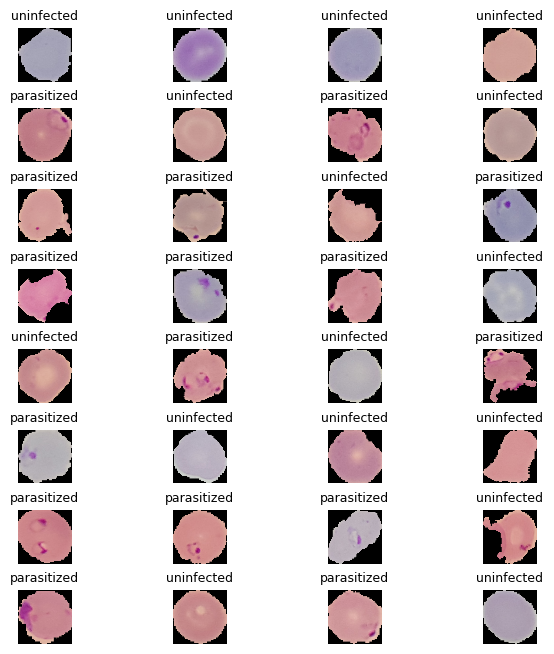

In [10]:
# Visualize some of the training set - make sure we know how to access images and labels
class_names = train_dataset.class_names

if not(SAVE_TIME):
  plt.figure(figsize=(8, 8))
  ds = train_dataset.take(1)
  for images, label in ds:
    for i in range(32):
      ax = plt.subplot(8, 4, i + 1)
      plt.imshow(images[i].numpy().astype("uint8"))
      plt.title(class_names[int(label[i])], fontsize=9)
      plt.axis("off")
  plt.subplots_adjust(wspace=0, hspace=0.5)
  plt.show()

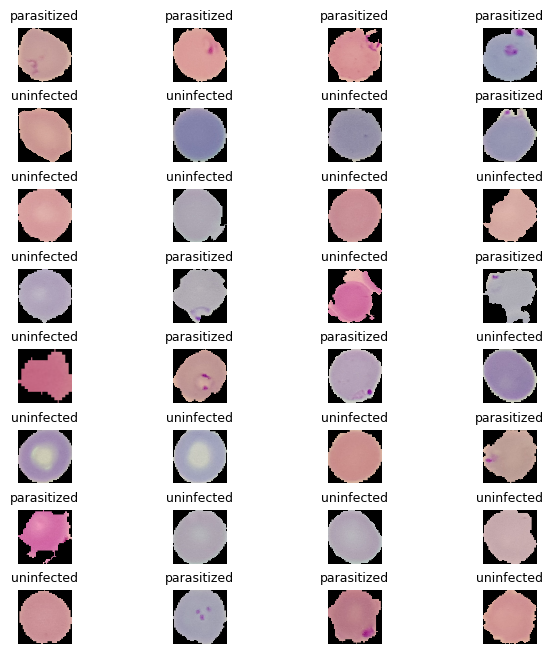

In [11]:
# Visualize some of the test set - make sure we know how to access images and labels

if not(SAVE_TIME):
  plt.figure(figsize=(8, 8))
  ds = test_dataset.take(1)
  for images, label in ds:
    for i in range(32):
      ax = plt.subplot(8, 4, i + 1)
      plt.imshow(images[i].numpy().astype("uint8"))
      plt.title(class_names[int(label[i])], fontsize=9)
      plt.axis("off")
  plt.subplots_adjust(wspace=0, hspace=0.5)
  plt.show()

### Configure the datasets for improved i/o performance

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

This is how we can apply image processing to images before training/testing.

size = (150, 150)

train_ds = train_ds.map(lambda x, y: (tf.image.resize(x, size), y))

validation_ds = validation_ds.map(lambda x, y: (tf.image.resize(x, size), y))

test_ds = test_ds.map(lambda x, y: (tf.image.resize(x, size), y))


# Build a CNN Model. This can be saved and used to benchmark enhanced images from various image processing techniques in the next EDA.

In [13]:
# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [14]:
# Clearing the backend
from keras import backend
backend.clear_session()

In [15]:
num_classes = 1

base_model = keras.Sequential([
  keras.layers.Rescaling(1./255),
  keras.layers.Conv2D(32, 3, activation='relu'),
  keras.layers.MaxPooling2D(),
  keras.layers.Conv2D(32, 3, activation='relu'),
  keras.layers.MaxPooling2D(),
  keras.layers.Conv2D(32, 3, activation='relu'),
  keras.layers.MaxPooling2D(),
  keras.layers.Flatten(),
  keras.layers.Dense(128, activation='relu'),
  keras.layers.Dense(num_classes, activation='sigmoid')
])

In [16]:
# For now we will use these parameters. We may want to use a different optimizer or metric to tune performance later.
base_model.compile(
  optimizer = keras.optimizers.Adam(learning_rate=0.001), #use_ema=False, ema_momentum=0.99),
  loss = tf.keras.losses.BinaryCrossentropy(from_logits=True),
  metrics=[keras.metrics.BinaryAccuracy()])

In [17]:
history_base = base_model.fit(
  train_dataset,
  validation_data = validation_dataset,
  epochs=3
)

Epoch 1/3
585/585 [==============================] - 236s 402ms/step - loss: 0.3400 - binary_accuracy: 0.8570 - val_loss: 0.1905 - val_binary_accuracy: 0.9356
Epoch 2/3
585/585 [==============================] - 233s 398ms/step - loss: 0.1942 - binary_accuracy: 0.9373 - val_loss: 0.1558 - val_binary_accuracy: 0.9535
Epoch 3/3
585/585 [==============================] - 235s 401ms/step - loss: 0.1480 - binary_accuracy: 0.9526 - val_loss: 0.1563 - val_binary_accuracy: 0.9527


In [18]:
history_base.history.keys()

dict_keys(['loss', 'binary_accuracy', 'val_loss', 'val_binary_accuracy'])

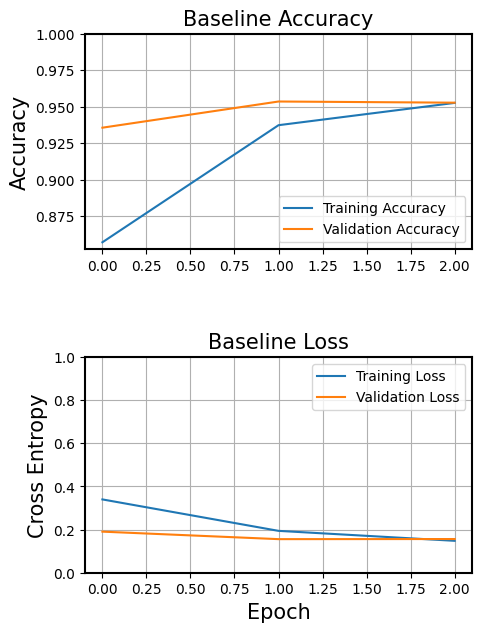

In [19]:
# Look at training performance
acc = history_base.history['binary_accuracy']
val_acc = history_base.history['val_binary_accuracy']

loss = history_base.history['loss']
val_loss = history_base.history['val_loss']

plt.figure(figsize=(5, 7))
plt.subplot(2, 1, 1)
plt.grid()
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Baseline Accuracy')

plt.subplot(2, 1, 2)
plt.grid()
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Baseline Loss')
plt.xlabel('Epoch')
plt.subplots_adjust(wspace=0, hspace=0.5)
plt.show()

### Save the baseline model

We can save a model with `keras.models.save_model()`. You can load it back with `keras.models.load_model()`.


In [20]:
keras.models.save_model(base_model, myModelsPath+"BaseModel_ThreeEpochs", overwrite=True, save_format="keras")

In [21]:
# Confirm the model can be re-loaded and used for predictions.
loaded_model = tf.keras.models.load_model(myModelsPath+"BaseModel_ThreeEpochs")
ds = test_dataset.take(5)
for x, tlabel in ds:
  assert np.allclose(base_model.predict(x), loaded_model.predict(x))

1/1 [==============================] - 0s 86ms/step


In [22]:
base_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 224, 224, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 222, 222, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 111, 111, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 109, 109, 32)      9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 54, 54, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 52, 52, 32)        9

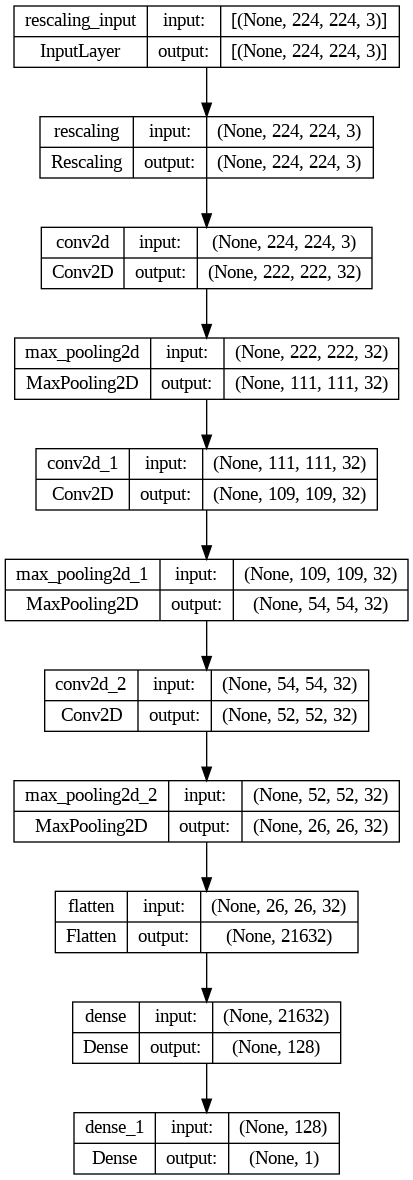

In [23]:
from keras.utils.vis_utils import plot_model
plot_model(base_model, to_file=myModelsPath+'BaseModel_plot.png', show_shapes=True, show_layer_names=True)

## Evaluate the Base Model with Test dataset

In [24]:
test_labels = np.concatenate([y for x, y in test_dataset], axis=0)
pd.value_counts(test_labels.tolist())

[1.0]    1300
[0.0]    1300
dtype: int64

In [25]:
result = base_model.evaluate(test_dataset)
dict(zip(base_model.metrics_names, result))

82/82 [==============================] - 5s 59ms/step - loss: 0.1701 - binary_accuracy: 0.9442


{'loss': 0.17005479335784912, 'binary_accuracy': 0.9442307949066162}

from sklearn.metrics import roc_curve

fpr,tpr,thresholds=roc_curve(y_test,y_pred_prob)

In [26]:
y_pred = base_model.predict(test_dataset)


82/82 [==============================] - 5s 56ms/step


In [27]:
test_labels[:10]

array([[1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.]], dtype=float32)

In [28]:
y_pred[:10]

array([[0.9993142 ],
       [0.99195856],
       [0.9953369 ],
       [0.00346317],
       [0.98278123],
       [0.95638365],
       [0.58249366],
       [0.98181677],
       [0.65435684],
       [0.2443005 ]], dtype=float32)

In [29]:
y_pred_fixed = tf.where(y_pred <0.5, 0,1)
y_pred_fixed[:10]

<tf.Tensor: shape=(10, 1), dtype=int32, numpy=
array([[1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0]], dtype=int32)>

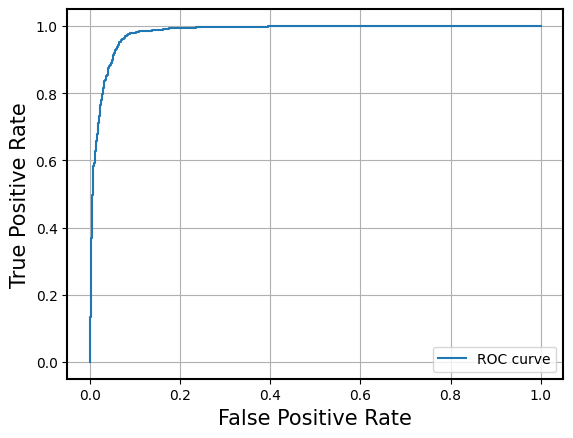

In [30]:
# Produce a ROC curve from y_pred and test_labels

from sklearn.metrics import roc_curve, roc_auc_score
fpr,tpr,thresholds=roc_curve(test_labels, y_pred)
plt.plot(fpr,tpr,label="ROC curve")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid()
plt.show()


In [31]:
# Get the area under the ROC curve using test_labels and y_pred

auc = roc_auc_score(test_labels, y_pred)
print("Area under the ROC curve:", auc)


Area under the ROC curve: 0.9811852071005916
